## 1. Install required libraries

In [1]:
!pip install -q transformers datasets scikit-learn accelerate

## 2. Load a sample of the IMDB dataset

In [2]:
import numpy as np, torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report

SEED = 42
TRAIN_SIZE, TEST_SIZE = 2000, 500   # increase for better accuracy
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# "stanfordnlp/imdb" is the current official name; fall back to the old name if needed
try:
    dataset = load_dataset("stanfordnlp/imdb")
except Exception as e:
    print("Primary load failed, trying fallback:", e)
    dataset = load_dataset("imdb")

train_ds = dataset["train"].shuffle(seed=SEED).select(range(TRAIN_SIZE))
test_ds = dataset["test"].shuffle(seed=SEED).select(range(TEST_SIZE))

print(train_ds)
print("Label counts (train):", np.bincount(train_ds["label"]))
print("\nExample:", train_ds[0]["text"][:200], "...", "| label:", train_ds[0]["label"])

Using device: cuda


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label'],
    num_rows: 2000
})
Label counts (train): [1000 1000]

Example: There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. F ... | label: 1


## 3. Tokenize text using the BERT tokenizer

In [3]:
from transformers import AutoTokenizer

MODEL_NAME = "bert-base-uncased"
MAX_LEN = 256   # lower to 128 for faster training
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)

train_tok = train_ds.map(tokenize, batched=True)
test_tok = test_ds.map(tokenize, batched=True)
print(train_tok)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 2000
})


## 4. Fine-tune pre-trained BERT

In [4]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"}, label2id={"NEGATIVE": 0, "POSITIVE": 1})

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary")
    return {"accuracy": accuracy_score(labels, preds), "precision": p, "recall": r, "f1": f1}

args_kwargs = dict(
    output_dir="bert-imdb",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    save_strategy="no",
    fp16=torch.cuda.is_available(),
    logging_steps=50,
    report_to="none",
    seed=SEED,
)
try:
    args = TrainingArguments(eval_strategy="epoch", **args_kwargs)
except TypeError:   # older transformers versions
    args = TrainingArguments(evaluation_strategy="epoch", **args_kwargs)

trainer = Trainer(
    model=model, args=args,
    train_dataset=train_tok, eval_dataset=test_tok,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.395321,0.285247,0.876000,0.835766,0.930894,0.880769
2,0.189247,0.287611,0.894000,0.872587,0.918699,0.895050


TrainOutput(global_step=250, training_loss=0.31974397659301756, metrics={'train_runtime': 59.8489, 'train_samples_per_second': 66.835, 'train_steps_per_second': 4.177, 'total_flos': 526222110720000.0, 'train_loss': 0.31974397659301756, 'epoch': 2.0})

## 5. Evaluate: Accuracy, Precision, Recall, F1

Accuracy : 0.8940
Precision: 0.8726
Recall   : 0.9187
F1-score : 0.8950

              precision    recall  f1-score   support

    Negative       0.92      0.87      0.89       254
    Positive       0.87      0.92      0.90       246

    accuracy                           0.89       500
   macro avg       0.89      0.89      0.89       500
weighted avg       0.90      0.89      0.89       500



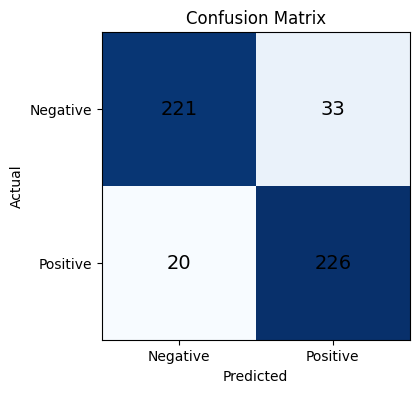

In [5]:
pred_out = trainer.predict(test_tok)
y_true = pred_out.label_ids
y_pred = np.argmax(pred_out.predictions, axis=-1)

print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary")
print(f"Precision: {p:.4f}\nRecall   : {r:.4f}\nF1-score : {f1:.4f}\n")
print(classification_report(y_true, y_pred, target_names=["Negative", "Positive"]))

import matplotlib.pyplot as plt
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Negative", "Positive"]); ax.set_yticklabels(["Negative", "Positive"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Confusion Matrix")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="black", fontsize=14)
plt.show()

## 6. Test on new sentences

In [6]:
from transformers import pipeline

clf = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer,
               device=0 if torch.cuda.is_available() else -1)

sentences = [
    "This movie was absolutely fantastic, I loved every minute of it!",
    "Terrible plot and awful acting. A complete waste of time.",
    "The visuals were stunning, but the story felt a bit slow.",
    "I would happily watch this film again with my family.",
    "Boring, predictable, and way too long.",
]
for s, out in zip(sentences, clf(sentences, truncation=True, max_length=MAX_LEN)):
    print(f"{out['label']:8s} ({out['score']:.2%})  {s}")

POSITIVE (97.42%)  This movie was absolutely fantastic, I loved every minute of it!
NEGATIVE (97.10%)  Terrible plot and awful acting. A complete waste of time.
NEGATIVE (66.71%)  The visuals were stunning, but the story felt a bit slow.
POSITIVE (93.79%)  I would happily watch this film again with my family.
NEGATIVE (94.17%)  Boring, predictable, and way too long.
